In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import mannwhitneyu, chi2_contingency

import os
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [2]:
PROCESSED_PATH = "../data/processed/"

play_features_path = (
    PROCESSED_PATH + "play_level_features.csv"
)

injury_features_path = (
    PROCESSED_PATH + "injury_enriched_features.csv"
)

In [3]:
play_features = pd.read_csv(
    play_features_path,
    dtype={"PlayKey": "string"}
)

injury_enriched = pd.read_csv(
    injury_features_path,
    dtype={"PlayKey": "string"}
)

print("Play-level dataset:", play_features.shape)
print("Injury dataset:", injury_enriched.shape)

display(play_features.head())
display(injury_enriched.head())

Play-level dataset: (267005, 34)
Injury dataset: (77, 41)


,PlayerKey,GameID,PlayKey,RosterPosition,PlayerDay,PlayerGame,StadiumType,FieldType,Temperature,Weather,...,y_max,duration,speed_mean,speed_std,acceleration_mean,acceleration_abs_mean,x_range,y_range,is_synthetic,temperature_category
0,26624,26624-1,26624-1-1,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,29.85,29.8,0.535753,0.607923,-0.000336,0.339262,7.13,6.23,1,Moderate
1,26624,26624-1,26624-1-2,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,29.96,25.9,0.849692,0.617141,0.041313,0.386486,10.18,2.61,1,Moderate
2,26624,26624-1,26624-1-3,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,29.63,29.5,0.331014,0.487729,0.043729,0.158983,4.33,3.89,1,Moderate
3,26624,26624-1,26624-1-4,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,27.71,12.6,0.523701,0.529241,0.075397,0.353175,3.09,3.08,1,Moderate
4,26624,26624-1,26624-1-5,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,26.41,25.9,0.970385,0.869971,0.049807,0.268340,20.47,4.48,1,Moderate


,PlayerKey_injury,GameID_injury,PlayKey,BodyPart,Surface,DM_M1,DM_M7,DM_M28,DM_M42,PlayerKey_playlist,...,x_max,y_min,y_max,duration,speed_mean,speed_std,acceleration_mean,acceleration_abs_mean,x_range,y_range
0,39873,39873-4,39873-4-32,Knee,Synthetic,1,1,1,1,39873,...,93.45,17.30,46.63,44.1,1.489140,2.417293,-0.016780,0.580952,37.27,29.33
1,46074,46074-7,46074-7-26,Knee,Natural,1,1,0,0,46074,...,95.29,23.66,28.91,22.2,2.024215,2.422019,0.003604,0.836937,40.67,5.25
2,36557,36557-1,36557-1-70,Ankle,Synthetic,1,1,1,1,36557,...,84.01,10.64,30.59,15.9,1.574938,1.981710,-0.020126,0.810063,10.71,19.95
3,46646,46646-3,46646-3-30,Ankle,Natural,1,0,0,0,46646,...,71.11,18.55,31.13,24.9,2.194320,2.605092,0.001205,0.698394,47.09,12.58
4,43532,43532-5,43532-5-69,Ankle,Synthetic,1,1,1,1,43532,...,75.47,45.27,49.23,34.9,0.760543,1.204567,-0.006017,0.408883,19.96,3.96


In [4]:
print("Surface distribution:")

print(
    play_features["FieldType"].value_counts(
        dropna=False
    )
)

print("\nMissing surface values:")

print(
    play_features["FieldType"].isna().sum()
)

Surface distribution:
FieldType
natural      156902
synthetic    110103
Name: count, dtype: int64

Missing surface values:
0


In [5]:
# Keep only records with known playing surfaces
surface_data = play_features[
    play_features["FieldType"].isin(
        ["natural", "synthetic"]
    )
].copy()

injury_data = injury_enriched[
    injury_enriched["FieldType"].isin(
        ["natural", "synthetic"]
    )
].copy()

print("Valid play records:", len(surface_data))
print("Valid injury records:", len(injury_data))

print("\nSurface counts:")
print(surface_data["FieldType"].value_counts())

Valid play records: 267005
Valid injury records: 0

Surface counts:
FieldType
natural      156902
synthetic    110103
Name: count, dtype: int64


FieldType
natural      156902
synthetic    110103
Name: count, dtype: int64

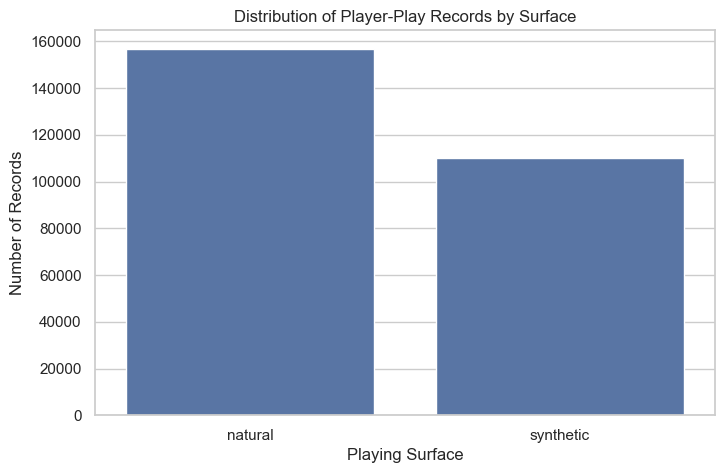

In [6]:
surface_counts = (
    surface_data["FieldType"]
    .value_counts()
    .reindex(["natural", "synthetic"])
)

display(surface_counts)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=surface_counts.index,
    y=surface_counts.values
)

plt.title("Distribution of Player-Play Records by Surface")
plt.xlabel("Playing Surface")
plt.ylabel("Number of Records")

plt.show()

In [7]:
surface_percentages = (
    surface_data["FieldType"]
    .value_counts(normalize=True) * 100
)

display(
    surface_percentages.rename("Percentage")
    .to_frame()
)

,Percentage
FieldType,
natural,58.763694
synthetic,41.236306


In [8]:
movement_features = [
    "speed_mean",
    "speed_max",
    "speed_std",
    "distance_total",
    "acceleration_abs_mean",
    "acceleration_abs_max",
    "duration",
    "x_range",
    "y_range"
]

surface_summary = (
    surface_data
    .groupby("FieldType")[movement_features]
    .agg(["count", "mean", "median", "std"])
)

display(surface_summary)

speed_mean                               speed_max                   \
               count      mean    median       std     count      mean median   
FieldType                                                                       
natural       156876  1.302849  1.178179  0.709870    156876  4.806098   4.61   
synthetic     110084  1.361714  1.229618  0.758187    110084  4.905794   4.70   

                    speed_std            ... duration            x_range  \
                std     count      mean  ...   median        std   count   
FieldType                                ...                               
natural    2.002353    156876  1.300773  ...     27.7  11.959118  156876   
synthetic  2.059309    110084  1.349126  ...     26.5  12.300534  110084   

                                       y_range                              
                mean median        std   count       mean median       std  
FieldType                                                                   
natural    15.532153  11.56  12.718568  156876  14.457141  12.54  9.451395  
synthetic  15.846077  11.60  13.115277  110084  14.667941  12.80  9.658318  

[2 rows x 36 columns]

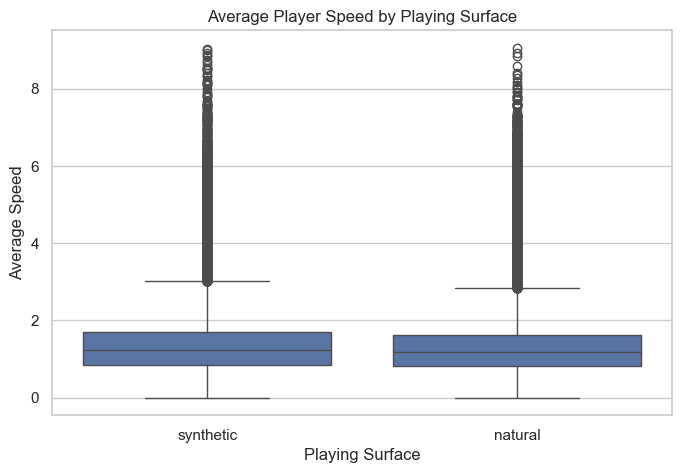

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=surface_data,
    x="FieldType",
    y="speed_mean"
)

plt.title("Average Player Speed by Playing Surface")
plt.xlabel("Playing Surface")
plt.ylabel("Average Speed")

plt.show()

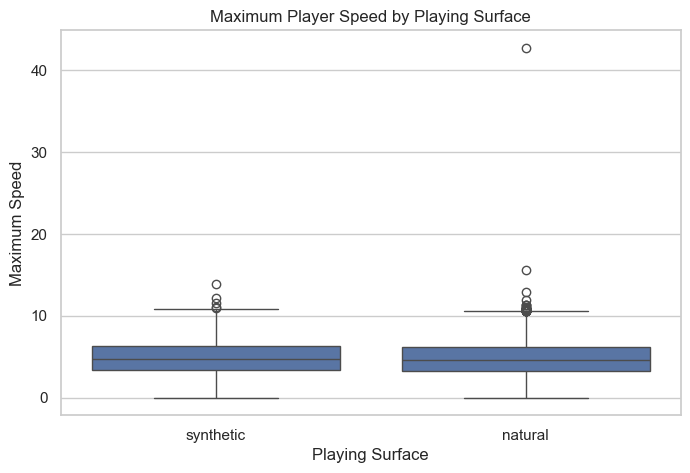

In [10]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=surface_data,
    x="FieldType",
    y="speed_max"
)

plt.title("Maximum Player Speed by Playing Surface")
plt.xlabel("Playing Surface")
plt.ylabel("Maximum Speed")

plt.show()

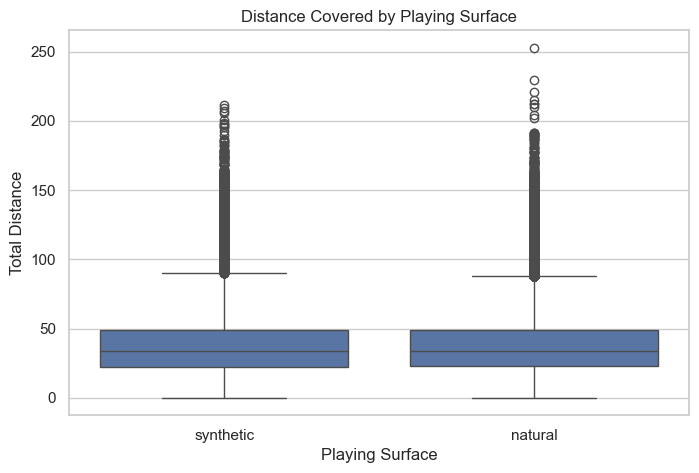

In [11]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=surface_data,
    x="FieldType",
    y="distance_total"
)

plt.title("Distance Covered by Playing Surface")
plt.xlabel("Playing Surface")
plt.ylabel("Total Distance")

plt.show()

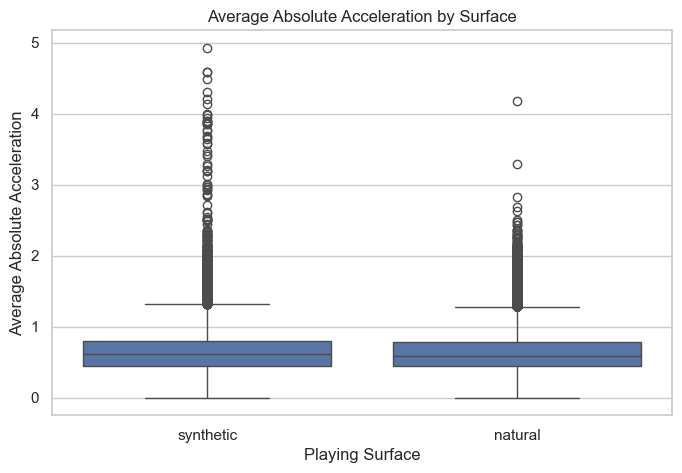

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=surface_data,
    x="FieldType",
    y="acceleration_abs_mean"
)

plt.title("Average Absolute Acceleration by Surface")
plt.xlabel("Playing Surface")
plt.ylabel("Average Absolute Acceleration")

plt.show()

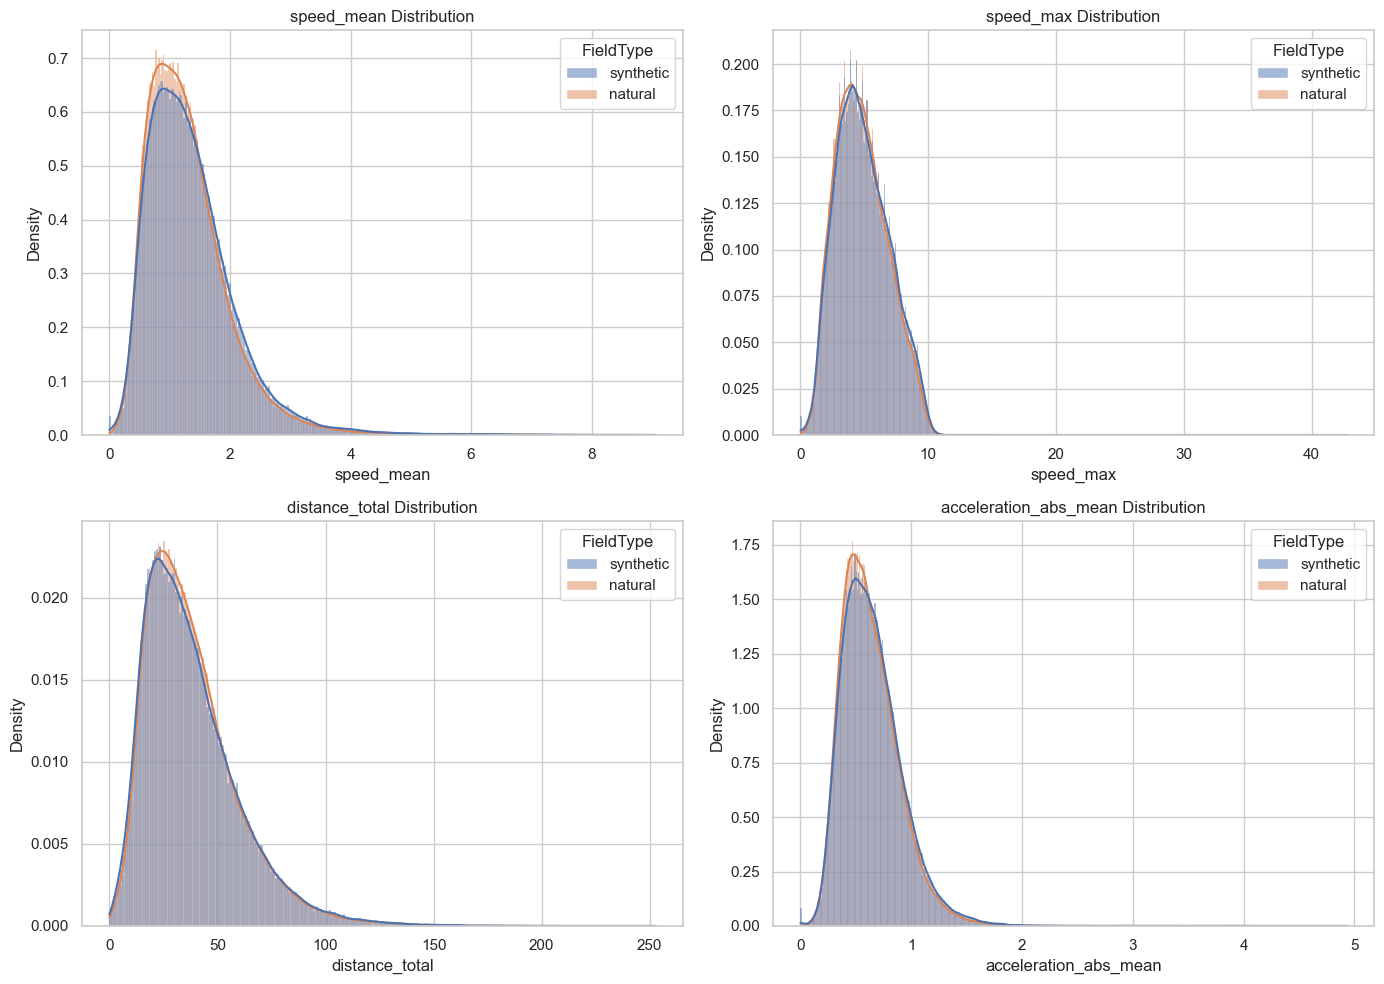

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

features_to_plot = [
    "speed_mean",
    "speed_max",
    "distance_total",
    "acceleration_abs_mean"
]

for ax, feature in zip(
    axes.flatten(),
    features_to_plot
):
    sns.histplot(
        data=surface_data,
        x=feature,
        hue="FieldType",
        kde=True,
        stat="density",
        common_norm=False,
        ax=ax
    )

    ax.set_title(f"{feature} Distribution")

plt.tight_layout()
plt.show()

In [14]:
statistical_results = []

for feature in movement_features:

    natural = surface_data.loc[
        surface_data["FieldType"] == "natural",
        feature
    ].dropna()

    synthetic = surface_data.loc[
        surface_data["FieldType"] == "synthetic",
        feature
    ].dropna()

    if len(natural) == 0 or len(synthetic) == 0:
        continue

    statistic, p_value = mannwhitneyu(
        natural,
        synthetic,
        alternative="two-sided"
    )

    statistical_results.append({
        "Feature": feature,
        "Natural_Median": natural.median(),
        "Synthetic_Median": synthetic.median(),
        "Natural_Count": len(natural),
        "Synthetic_Count": len(synthetic),
        "U_Statistic": statistic,
        "P_Value": p_value
    })

statistical_results = pd.DataFrame(
    statistical_results
)

display(
    statistical_results.sort_values("P_Value")
)

,Feature,Natural_Median,Synthetic_Median,Natural_Count,Synthetic_Count,U_Statistic,P_Value
6,duration,27.700000,26.500000,156876,110084,9.301081e+09,2.698293e-253
0,speed_mean,1.178179,1.229618,156876,110084,8.249138e+09,3.586404e-86
2,speed_std,1.186410,1.233231,156876,110084,8.286913e+09,1.816634e-70
4,acceleration_abs_mean,0.591632,0.611765,156876,110084,8.317601e+09,6.824899e-59
1,speed_max,4.610000,4.700000,156876,110084,8.405533e+09,1.347967e-31
8,y_range,12.540000,12.800000,156876,110084,8.548218e+09,1.006985e-05
5,acceleration_abs_max,3.600000,3.700000,156876,110084,8.553600e+09,3.456242e-05
3,distance_total,33.880000,33.590000,156876,110084,8.710746e+09,1.060936e-04
7,x_range,11.560000,11.600000,156876,110084,8.608167e+09,1.747245e-01


In [15]:
statistical_results["Significant_0.05"] = (
    statistical_results["P_Value"] < 0.05
)

display(
    statistical_results[
        [
            "Feature",
            "P_Value",
            "Significant_0.05"
        ]
    ]
)

,Feature,P_Value,Significant_0.05
0,speed_mean,3.586404e-86,True
1,speed_max,1.347967e-31,True
2,speed_std,1.816634e-70,True
3,distance_total,1.060936e-04,True
4,acceleration_abs_mean,6.824899e-59,True
5,acceleration_abs_max,3.456242e-05,True
6,duration,2.698293e-253,True
7,x_range,1.747245e-01,False
8,y_range,1.006985e-05,True


In [16]:
injury_counts = (
    injury_data.groupby("FieldType")["PlayKey"]
    .nunique()
    .reindex(["natural", "synthetic"], fill_value=0)
)

display(
    injury_counts.rename("Unique Injured PlayKeys").to_frame()
)

,Unique Injured PlayKeys
FieldType,
natural,0
synthetic,0


In [17]:
total_plays = (
    surface_data.groupby("FieldType")["PlayKey"]
    .nunique()
    .reindex(["natural", "synthetic"], fill_value=0)
)

injury_rate = pd.DataFrame({
    "Total_Player_Plays": total_plays,
    "Recorded_Injured_Plays": injury_counts
})

injury_rate["Rate_per_10000_plays"] = (
    injury_rate["Recorded_Injured_Plays"] /
    injury_rate["Total_Player_Plays"] * 10000
)

display(injury_rate)

,Total_Player_Plays,Recorded_Injured_Plays,Rate_per_10000_plays
FieldType,,,
natural,156902,0,0.0
synthetic,110103,0,0.0


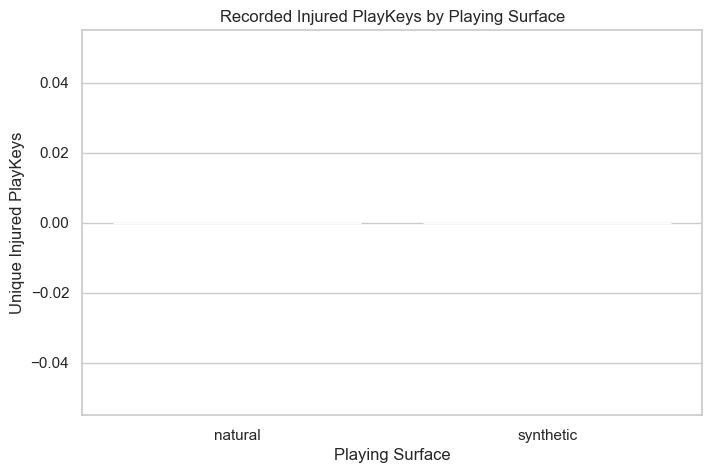

In [19]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=injury_counts.index,
    y=injury_counts.values
)

plt.title("Recorded Injured PlayKeys by Playing Surface")
plt.xlabel("Playing Surface")
plt.ylabel("Unique Injured PlayKeys")

plt.show()

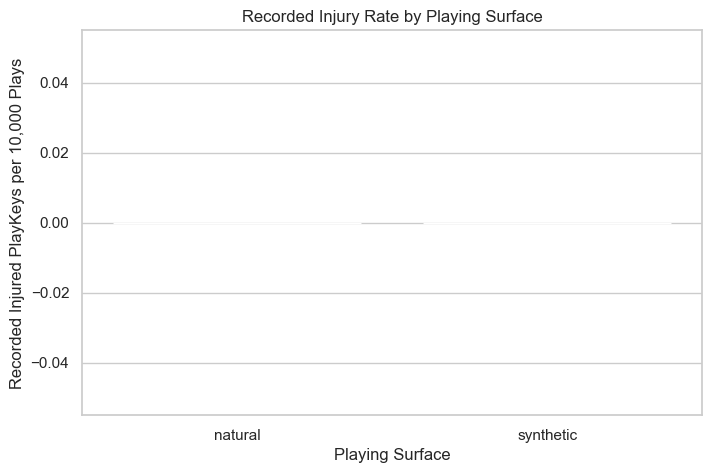

In [20]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=injury_rate.reset_index(),
    x="FieldType",
    y="Rate_per_10000_plays"
)

plt.title("Recorded Injury Rate by Playing Surface")
plt.xlabel("Playing Surface")
plt.ylabel("Recorded Injured PlayKeys per 10,000 Plays")

plt.show()

Series([], Name: count, dtype: int64)

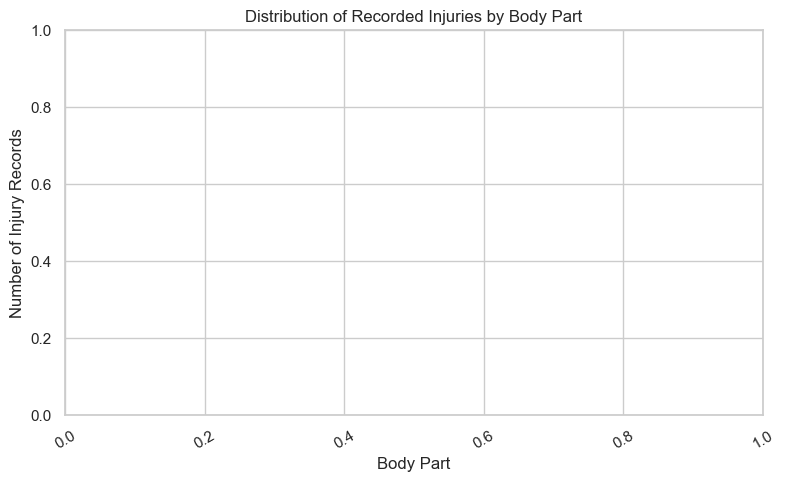

In [21]:
bodypart_counts = (
    injury_data["BodyPart"]
    .value_counts()
)

display(bodypart_counts)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=bodypart_counts.index,
    y=bodypart_counts.values
)

plt.title("Distribution of Recorded Injuries by Body Part")
plt.xlabel("Body Part")
plt.ylabel("Number of Injury Records")

plt.xticks(rotation=30)
plt.show()

FieldType
BodyPart


TypeError: no numeric data to plot

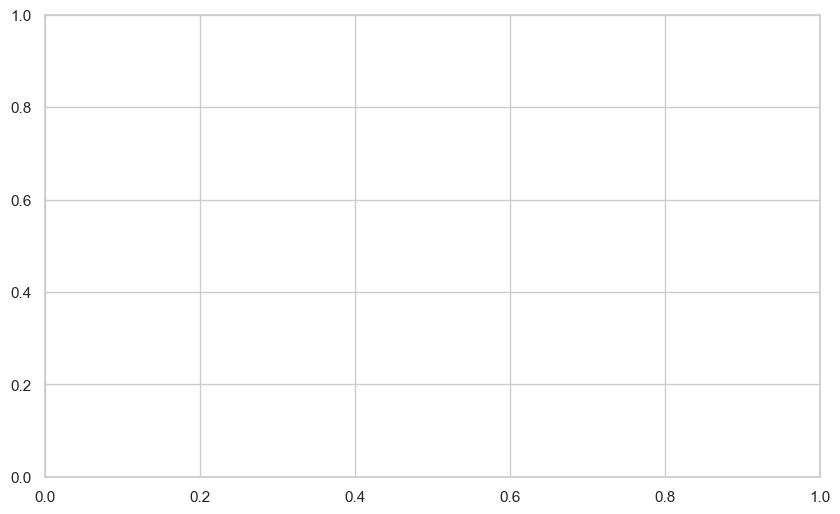

In [22]:
bodypart_surface = pd.crosstab(
    injury_data["BodyPart"],
    injury_data["FieldType"]
)

display(bodypart_surface)

bodypart_surface.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Body-Part Injury Records by Playing Surface")
plt.xlabel("Body Part")
plt.ylabel("Number of Injury Records")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [23]:
injured_playkeys = set(
    injury_data["PlayKey"].dropna().unique()
)

injury_test_data = surface_data[
    ["PlayKey", "FieldType"]
].drop_duplicates("PlayKey").copy()

injury_test_data["Injury_Recorded"] = (
    injury_test_data["PlayKey"].isin(injured_playkeys)
)

display(injury_test_data.head())

,PlayKey,FieldType,Injury_Recorded
0,26624-1-1,synthetic,False
1,26624-1-2,synthetic,False
2,26624-1-3,synthetic,False
3,26624-1-4,synthetic,False
4,26624-1-5,synthetic,False


In [24]:
contingency_table = pd.crosstab(
    injury_test_data["FieldType"],
    injury_test_data["Injury_Recorded"]
)

display(contingency_table)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_value)

if p_value < 0.05:
    print("Evidence of an association between surface and recorded injury labels.")
else:
    print("Insufficient evidence of an association.")

Injury_Recorded,False
FieldType,
natural,156902
synthetic,110103


Chi-square statistic: 0.0
Degrees of freedom: 0
P-value: 1.0
Insufficient evidence of an association.


In [25]:
surface_check = injury_data[
    ["PlayKey", "Surface", "FieldType"]
].copy()

surface_check["Surface"] = (
    surface_check["Surface"]
    .astype("string")
    .str.strip()
    .str.lower()
)

surface_check["FieldType"] = (
    surface_check["FieldType"]
    .astype("string")
    .str.strip()
    .str.lower()
)

surface_check["Surface_Match"] = (
    surface_check["Surface"] ==
    surface_check["FieldType"]
)

print(
    "Matching records:",
    surface_check["Surface_Match"].sum()
)

print(
    "Mismatching records:",
    (~surface_check["Surface_Match"]).sum()
)

display(
    surface_check[
        surface_check["Surface_Match"] == False
    ].head(10)
)

Matching records: 0
Mismatching records: 0


,PlayKey,Surface,FieldType,Surface_Match


In [26]:
surface_summary.to_csv(
    PROCESSED_PATH + "surface_movement_summary.csv"
)

statistical_results.to_csv(
    PROCESSED_PATH + "surface_statistical_tests.csv",
    index=False
)

injury_rate.to_csv(
    PROCESSED_PATH + "surface_injury_rates.csv"
)

bodypart_surface.to_csv(
    PROCESSED_PATH + "bodypart_surface_analysis.csv"
)

print("Notebook 05 analysis results saved successfully.")

Notebook 05 analysis results saved successfully.
